## 1. 프로젝트 개요

# 03. Exploratory Data Analysis (EDA)

## HR Analytics: 직원 이직 요인 및 조직 관리 분석

### 1. 분석 목적

전처리가 완료된 데이터를 활용하여 직원들의 다양한 특성과 이직 여부 간의 관계를 탐색한다.

인구통계학적 특성, 조직 및 직무 특성, 급여 수준, 근무 환경 등을 기준으로 직원 집단을 구분하고 집단별 이직률을 비교한다.

이를 통해 이직률이 상대적으로 높은 직원 집단의 특성을 파악하고, 향후 통계적 가설 검정 및 조직 관리 전략 수립에 활용할 분석 가설을 도출한다.

### 2. 핵심 분석 질문

1. 전체 직원 중 이직 직원의 비율은 어느 정도인가?
2. 연령 및 성별에 따라 이직률에 차이가 있는가?
3. 부서와 직무에 따라 이직률이 다르게 나타나는가?
4. 급여와 근속연수는 이직 여부와 어떤 관계가 있는가?
5. 초과근무 및 직무 만족도에 따라 이직률이 달라지는가?

### 3. 주요 분석 지표

- Employee Count: 직원 수
- Attrition Count: 이직 직원 수
- Attrition Rate: 전체 직원 대비 이직 직원 비율

### 4. 분석 방법

- 집단별 빈도 및 비율 분석
- 그룹별 이직률 비교
- 분포 및 상관관계 시각화
- 주요 변수 간 관계 탐색


## 2. 라이브러리 및 데이터 불러오기

02_Data_Preprocessing 단계에서 저장한 전처리 데이터를 불러온다.

이후 분석에 필요한 라이브러리를 설정하고, 데이터의 기본 구조와 주요 변수를 확인한다.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["figure.figsize"] = (10, 5)
sns.set_theme(style="whitegrid")

hr_df = pd.read_csv(
    "../data/processed/hr_preprocessed.csv"
)

print("데이터 크기:", hr_df.shape)

display(hr_df.head())

데이터 크기: (1470, 34)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeNumber,EnvironmentSatisfaction,...,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,TenureGroup,AttritionBinary
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,2,...,0,8,0,1,6,4,0,5,6-10 Years,1
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,2,3,...,1,10,3,3,10,7,1,7,6-10 Years,0
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,4,...,0,7,3,3,0,0,0,0,0-1 Years,1
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,5,4,...,0,8,3,3,8,7,3,0,6-10 Years,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,7,1,...,1,6,3,3,2,2,2,2,2-3 Years,0


## 3. 핵심 지표 설정 및 전체 이직률 분석

## 3. 전체 이직 현황 분석

본격적인 집단별 분석에 앞서 전체 직원 중 이직 직원이 차지하는 비율을 확인한다.

이직률은 전체 직원 수 대비 이직 직원 수의 비율로 정의한다.

이를 통해 분석 대상 데이터의 전반적인 이직 수준을 파악하고, 이후 집단별 이직률을 비교하기 위한 기준을 마련한다.

### 핵심 지표 정의

- 전체 직원 수: 분석 대상 직원의 총인원
- 이직 직원 수: Attrition이 Yes인 직원 수
- 이직률: 이직 직원 수 / 전체 직원 수 × 100

In [2]:
total_employees = len(hr_df)

attrition_count = (
    hr_df["Attrition"] == "Yes"
).sum()

retained_count = (
    hr_df["Attrition"] == "No"
).sum()

attrition_rate = (
    attrition_count / total_employees * 100
)

print(f"전체 직원 수: {total_employees:,}명")
print(f"이직 직원 수: {attrition_count:,}명")
print(f"재직 직원 수: {retained_count:,}명")
print(f"전체 이직률: {attrition_rate:.2f}%")

전체 직원 수: 1,470명
이직 직원 수: 237명
재직 직원 수: 1,233명
전체 이직률: 16.12%


In [3]:
attrition_summary = pd.DataFrame({
    "구분": ["재직", "이직"],
    "직원 수": [retained_count, attrition_count],
    "비율(%)": [
        retained_count / total_employees * 100,
        attrition_count / total_employees * 100
    ]
})

display(
    attrition_summary.style
    .background_gradient(cmap="Blues", subset=["비율(%)"])
    .format({"비율(%)": "{:.2f}"})
)

,구분,직원 수,비율(%)
0,재직,1233,83.88
1,이직,237,16.12


## 4. 인구통계학적 특성에 따른 이직률 분석

직원의 인구통계학적 특성에 따라 이직 현황에 차이가 나타나는지 분석한다.

연령, 성별, 결혼 여부를 기준으로 직원을 구분하고 각 집단의 직원 수와 이직률을 비교한다.

이를 통해 특정 인구통계학적 집단에서 상대적으로 높은 이직률이 관찰되는지 확인한다.

단, 집단별 이직률 차이는 해당 특성과 이직 간의 연관성을 보여주는 것이며, 직접적인 원인으로 해석하지 않는다.

In [4]:
### 집단별 이직률 함수
def calculate_attrition_rate(df, group_col):
    result = (
        df.groupby(group_col, observed=True)
        .agg(
            employee_count=("Attrition", "size"),
            attrition_count=(
                "Attrition",
                lambda x: (x == "Yes").sum()
            )
        )
        .reset_index()
    )

    result["attrition_rate"] = (
        result["attrition_count"]
        / result["employee_count"] * 100
    )

    return result.sort_values(
        "attrition_rate", ascending=False
    )

### 4-1. 연령대별 이직률 분석

연령에 따른 이직 현황을 비교하기 위해 직원을 연령 구간별로 분류한다.

연령대별 직원 수와 이직률을 함께 확인하여 연령 집단에 따른 이직 패턴을 탐색한다.

In [6]:
hr_df["AgeGroup"] = pd.cut(
    hr_df["Age"],
    bins=[0, 25, 35, 45, 55, np.inf],
    labels=[
        "Under 25",
        "25-34",
        "35-44",
        "45-54",
        "55+"
    ],
    right=False
)

age_result = calculate_attrition_rate(
    hr_df, "AgeGroup"
)

display(
    age_result.style
    .background_gradient(
        cmap="YlOrRd",
        subset=["attrition_rate"]
    )
    .format({"attrition_rate": "{:.2f}%"})
)

,AgeGroup,employee_count,attrition_count,attrition_rate
0,Under 25,97,38,39.18%
1,25-34,554,112,20.22%
4,55+,69,11,15.94%
3,45-54,245,25,10.20%
2,35-44,505,51,10.10%


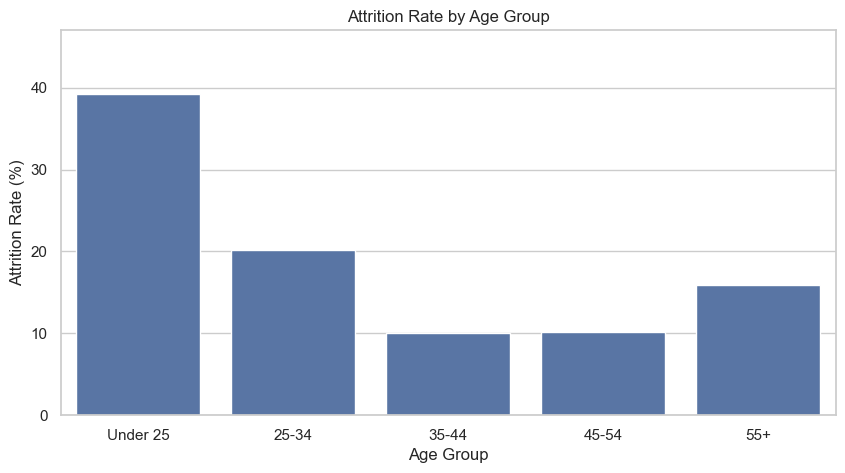

In [7]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=age_result,
    x="AgeGroup",
    y="attrition_rate"
)

plt.title("Attrition Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Attrition Rate (%)")
plt.ylim(0, age_result["attrition_rate"].max() * 1.2)

plt.show()

### 4-2. 성별 및 결혼 여부에 따른 이직률 분석

성별과 결혼 여부에 따른 이직률을 비교한다.

각 집단의 직원 수와 이직률을 함께 확인하여 집단 규모에 따른 해석 오류를 방지한다.

In [8]:
gender_result = calculate_attrition_rate(
    hr_df, "Gender"
)

marital_result = calculate_attrition_rate(
    hr_df, "MaritalStatus"
)

display(gender_result)
display(marital_result)

,Gender,employee_count,attrition_count,attrition_rate
1,Male,882,150,17.006803
0,Female,588,87,14.795918


,MaritalStatus,employee_count,attrition_count,attrition_rate
2,Single,470,120,25.531915
1,Married,673,84,12.481426
0,Divorced,327,33,10.091743


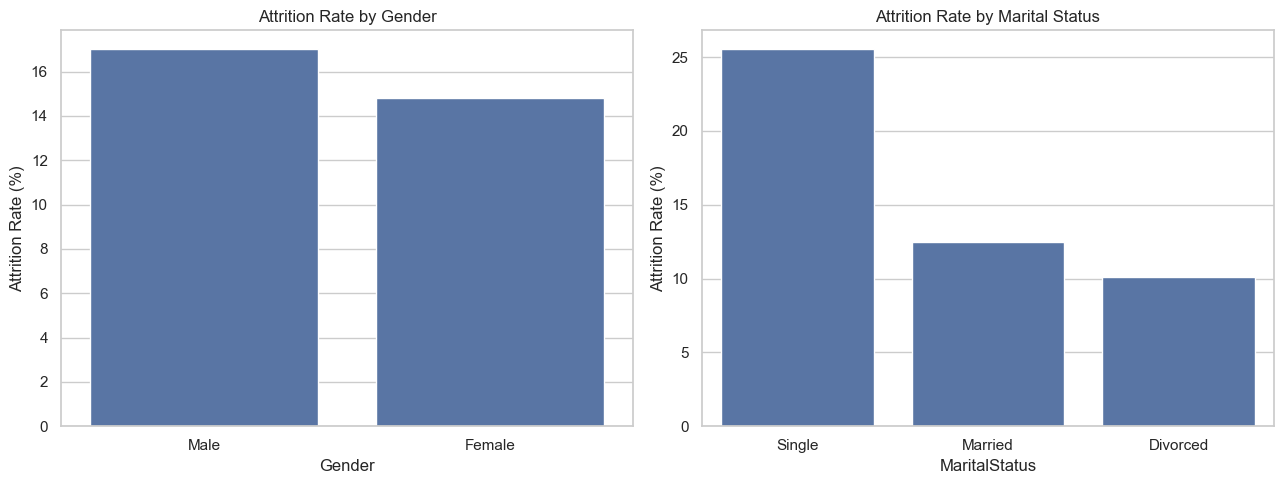

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=gender_result,
    x="Gender",
    y="attrition_rate",
    ax=axes[0]
)
axes[0].set_title("Attrition Rate by Gender")
axes[0].set_ylabel("Attrition Rate (%)")

sns.barplot(
    data=marital_result,
    x="MaritalStatus",
    y="attrition_rate",
    ax=axes[1]
)
axes[1].set_title("Attrition Rate by Marital Status")
axes[1].set_ylabel("Attrition Rate (%)")

plt.tight_layout()
plt.show()

## 5. 조직 및 직무 특성에 따른 이직률 분석

부서와 직무에 따라 직원들의 이직 현황에 차이가 있는지 분석한다.

부서별 이직률을 비교하여 조직 단위의 이직 패턴을 확인하고, 직무별 이직률을 추가적으로 비교하여 세부적인 직무 특성을 파악한다.

특정 부서 또는 직무에서 높은 이직률이 관찰될 경우, 해당 집단의 근무 환경과 업무 특성을 추가적으로 살펴볼 필요가 있다.

In [10]:
department_result = calculate_attrition_rate(
    hr_df, "Department"
)

jobrole_result = calculate_attrition_rate(
    hr_df, "JobRole"
)

display(department_result)
display(jobrole_result)

,Department,employee_count,attrition_count,attrition_rate
2,Sales,446,92,20.627803
0,Human Resources,63,12,19.047619
1,Research & Development,961,133,13.839750


,JobRole,employee_count,attrition_count,attrition_rate
8,Sales Representative,83,33,39.759036
2,Laboratory Technician,259,62,23.938224
1,Human Resources,52,12,23.076923
7,Sales Executive,326,57,17.484663
6,Research Scientist,292,47,16.095890
4,Manufacturing Director,145,10,6.896552
0,Healthcare Representative,131,9,6.870229
3,Manager,102,5,4.901961
5,Research Director,80,2,2.500000


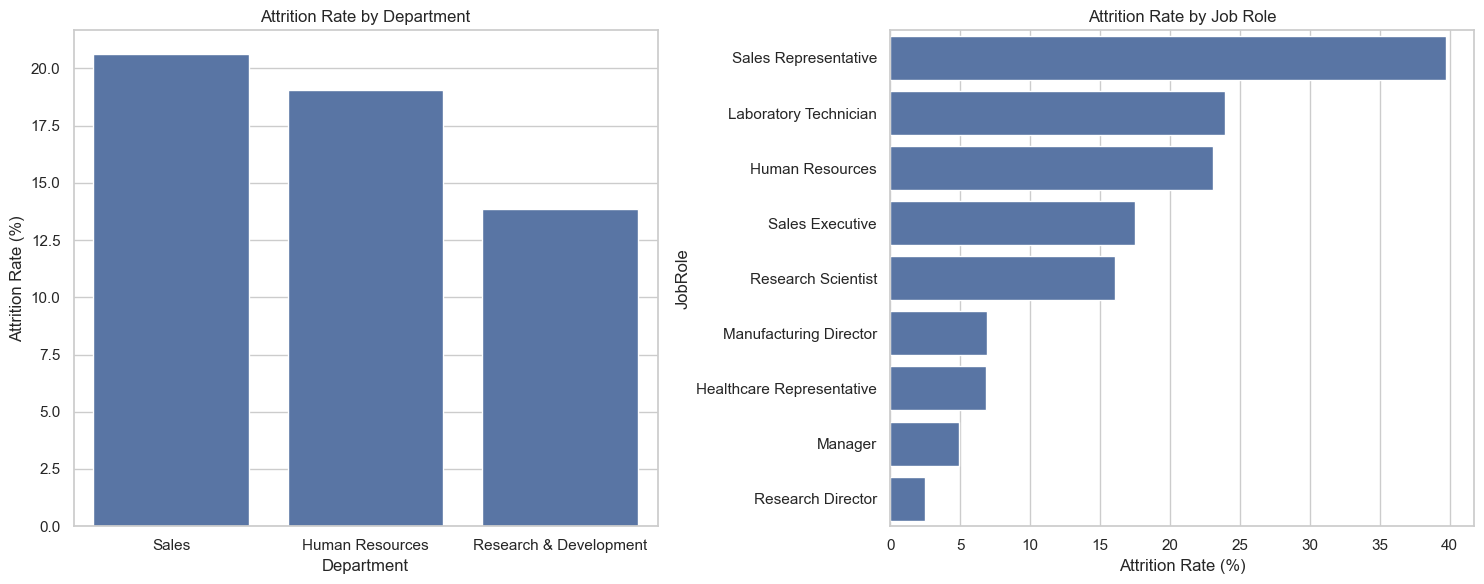

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.barplot(
    data=department_result,
    x="Department",
    y="attrition_rate",
    ax=axes[0]
)
axes[0].set_title("Attrition Rate by Department")
axes[0].set_ylabel("Attrition Rate (%)")

sns.barplot(
    data=jobrole_result,
    x="attrition_rate",
    y="JobRole",
    ax=axes[1]
)
axes[1].set_title("Attrition Rate by Job Role")
axes[1].set_xlabel("Attrition Rate (%)")

plt.tight_layout()
plt.show()

### 5-1. 부서 및 직무별 분석 결과

부서별 및 직무별 이직률을 비교하여 상대적으로 높은 이직률이 나타나는 집단을 확인한다.

해당 집단의 직원 수를 함께 고려하여 소규모 집단에서 발생할 수 있는 이직률의 변동성에 유의한다.

**주요 인사이트**

- [이직률이 상대적으로 높은 부서]
- [이직률이 상대적으로 높은 직무]
- [추가적인 원인 탐색이 필요한 조직 및 직무 특성]


## 6. 급여 및 근속연수에 따른 이직률 분석

직원의 급여 수준과 근속 기간에 따라 이직 현황이 어떻게 달라지는지 분석한다.

월 소득은 구간별로 분류하여 급여 수준에 따른 이직률을 비교하고, 근속연수는 사전에 생성한 TenureGroup 변수를 활용한다.

이를 통해 급여 및 조직 재직 기간과 이직 간의 관계를 탐색한다.


In [12]:
hr_df["IncomeGroup"] = pd.qcut(
    hr_df["MonthlyIncome"],
    q=4,
    labels=[
        "Q1 - Low",
        "Q2 - Middle Low",
        "Q3 - Middle High",
        "Q4 - High"
    ]
)

income_result = calculate_attrition_rate(
    hr_df, "IncomeGroup"
)

tenure_result = calculate_attrition_rate(
    hr_df, "TenureGroup"
)

display(income_result)
display(tenure_result)

,IncomeGroup,employee_count,attrition_count,attrition_rate
0,Q1 - Low,369,108,29.268293
1,Q2 - Middle Low,366,52,14.207650
2,Q3 - Middle High,367,39,10.626703
3,Q4 - High,368,38,10.326087


,TenureGroup,employee_count,attrition_count,attrition_rate
0,0-1 Years,215,75,34.883721
1,2-3 Years,255,47,18.431373
2,4-5 Years,306,40,13.071895
3,6-10 Years,448,55,12.276786
4,Over 10 Years,246,20,8.130081


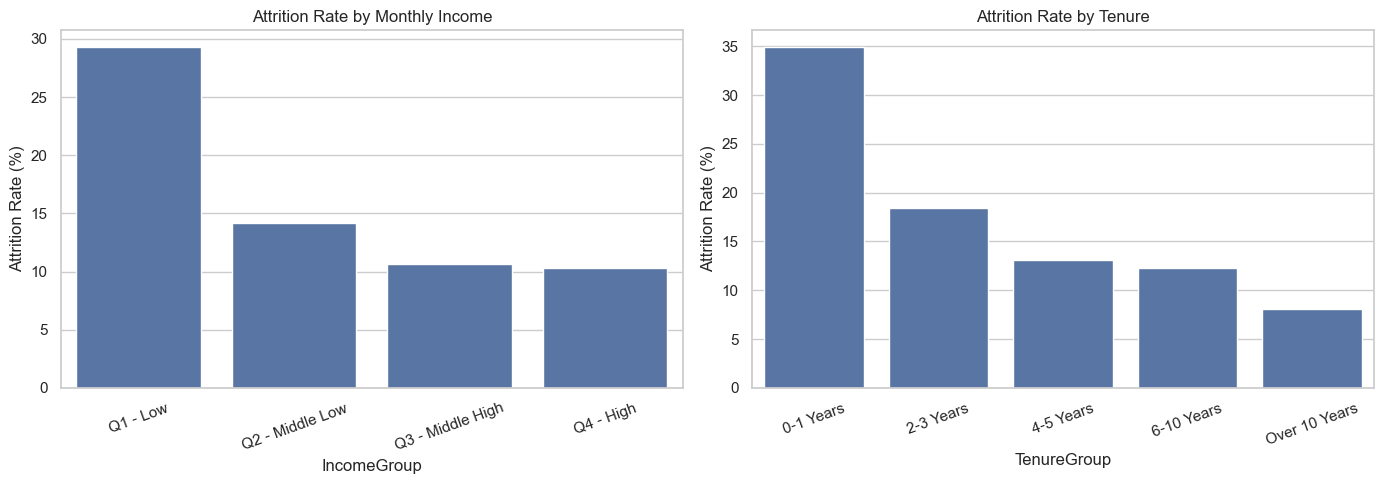

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=income_result,
    x="IncomeGroup",
    y="attrition_rate",
    ax=axes[0]
)
axes[0].set_title("Attrition Rate by Monthly Income")
axes[0].set_ylabel("Attrition Rate (%)")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(
    data=tenure_result,
    x="TenureGroup",
    y="attrition_rate",
    ax=axes[1]
)
axes[1].set_title("Attrition Rate by Tenure")
axes[1].set_ylabel("Attrition Rate (%)")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

### 6-1. 급여 및 근속연수 분석 결과

급여 수준과 근속 기간에 따른 이직률 차이를 비교한다.

급여 수준이 낮은 집단에서 이직률이 높게 나타나는지, 근속 기간이 짧은 직원 집단에서 상대적으로 높은 이직률이 관찰되는지 확인한다.

**주요 인사이트**

- [급여 구간별 이직률 차이]
- [근속연수별 이직률 차이]
- [추가적인 통계 분석이 필요한 변수]

## 7. 근무 환경 및 만족도에 따른 이직률 분석

직원의 근무 환경과 만족도 수준에 따라 이직 현황에 차이가 나타나는지 분석한다.

초과근무 여부, 직무 만족도, 근무 환경 만족도 및 워라밸을 중심으로 집단별 이직률을 비교한다.

이를 통해 직원의 근무 환경 및 조직 경험과 이직 간의 관계를 탐색한다.

,OverTime,employee_count,attrition_count,attrition_rate
1,Yes,416,127,30.528846
0,No,1054,110,10.436433


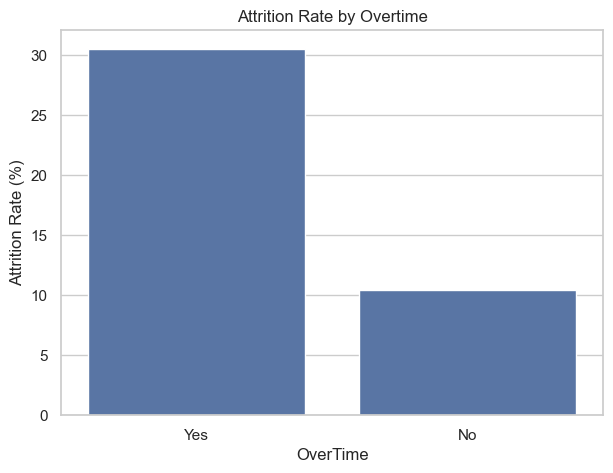

In [14]:
overtime_result = calculate_attrition_rate(
    hr_df, "OverTime"
)

display(overtime_result)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=overtime_result,
    x="OverTime",
    y="attrition_rate"
)

plt.title("Attrition Rate by Overtime")
plt.xlabel("OverTime")
plt.ylabel("Attrition Rate (%)")
plt.show()

### 7-1. 직무 만족도 및 워라밸에 따른 이직률 분석

직무 만족도, 근무 환경 만족도, 워라밸 수준에 따른 이직률을 비교한다.

각 변수는 등급 형태로 제공되므로 등급별 직원 수와 이직률을 함께 확인한다.

특정 만족도 수준에서 이직률이 높게 나타나는지 확인하고, 만족도와 이직 간의 관계를 탐색한다.

In [16]:
satisfaction_cols = [
    "JobSatisfaction",
    "EnvironmentSatisfaction",
    "WorkLifeBalance",
    "RelationshipSatisfaction"
]

satisfaction_results = {}

for col in satisfaction_cols:
    result = calculate_attrition_rate(hr_df, col)
    satisfaction_results[col] = result

    print(f"\n[{col}]")
    display(result)


[JobSatisfaction]


,JobSatisfaction,employee_count,attrition_count,attrition_rate
0,1,289,66,22.837370
2,3,442,73,16.515837
1,2,280,46,16.428571
3,4,459,52,11.328976



[EnvironmentSatisfaction]


,EnvironmentSatisfaction,employee_count,attrition_count,attrition_rate
0,1,284,72,25.352113
1,2,287,43,14.982578
2,3,453,62,13.686534
3,4,446,60,13.452915



[WorkLifeBalance]


,WorkLifeBalance,employee_count,attrition_count,attrition_rate
0,1,80,25,31.250000
3,4,153,27,17.647059
1,2,344,58,16.860465
2,3,893,127,14.221725



[RelationshipSatisfaction]


,RelationshipSatisfaction,employee_count,attrition_count,attrition_rate
0,1,276,57,20.652174
2,3,459,71,15.468410
1,2,303,45,14.851485
3,4,432,64,14.814815


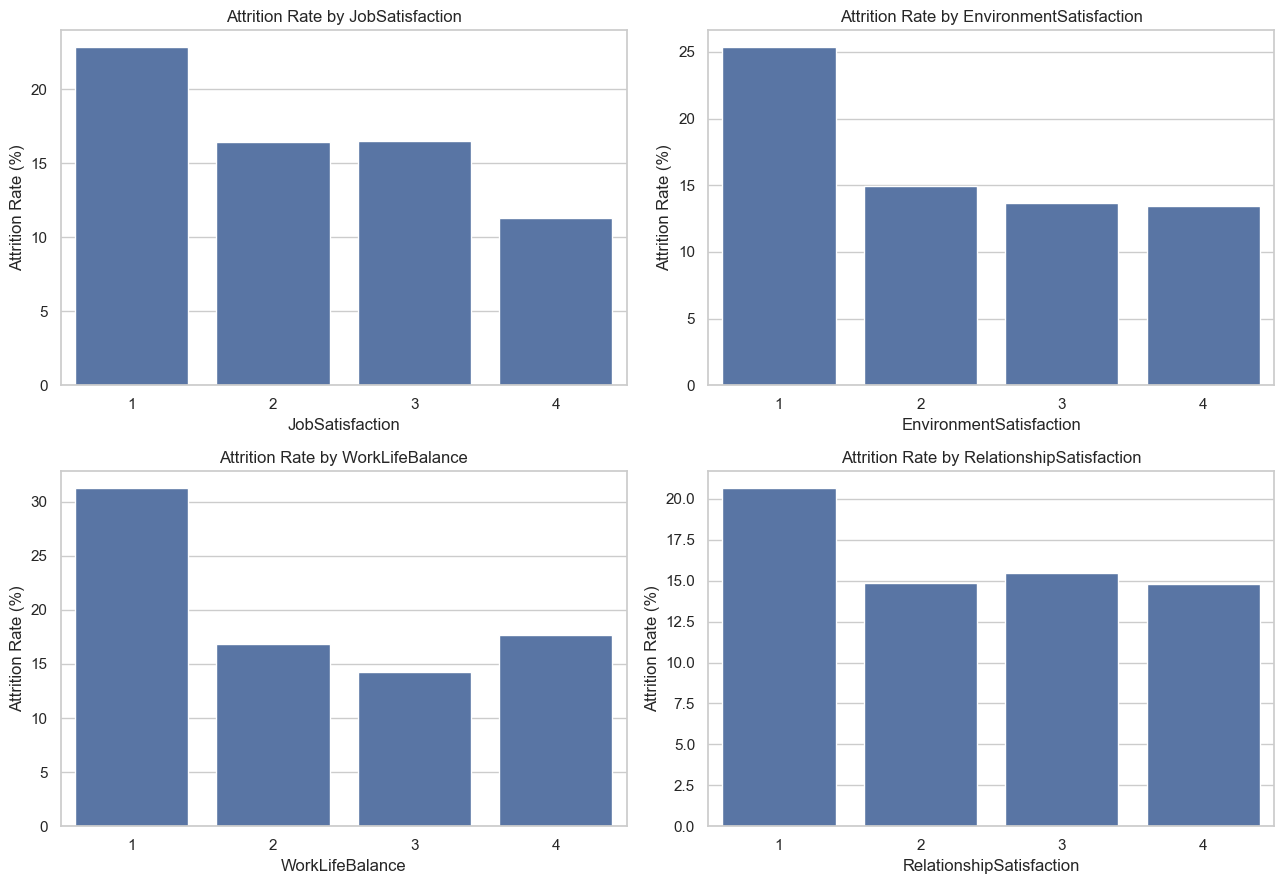

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()

for i, col in enumerate(satisfaction_cols):
    sns.barplot(
        data=satisfaction_results[col],
        x=col,
        y="attrition_rate",
        ax=axes[i]
    )

    axes[i].set_title(f"Attrition Rate by {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Attrition Rate (%)")

plt.tight_layout()
plt.show()

## 8. 이직 여부에 따른 주요 수치형 변수 분포 비교

이직 직원과 재직 직원 간의 주요 수치형 변수 분포를 비교한다.

월 소득, 연령, 근속연수, 현재 직무 근속연수 등의 변수를 중심으로 두 집단의 중앙값과 분포 차이를 확인한다.

이를 통해 집단별 이직률 비교만으로 파악하기 어려운 직원 특성의 차이를 추가적으로 탐색한다.

단, 분포 차이가 관찰되더라도 통계적으로 유의한 차이인지는 별도의 가설 검정을 통해 확인해야 한다.

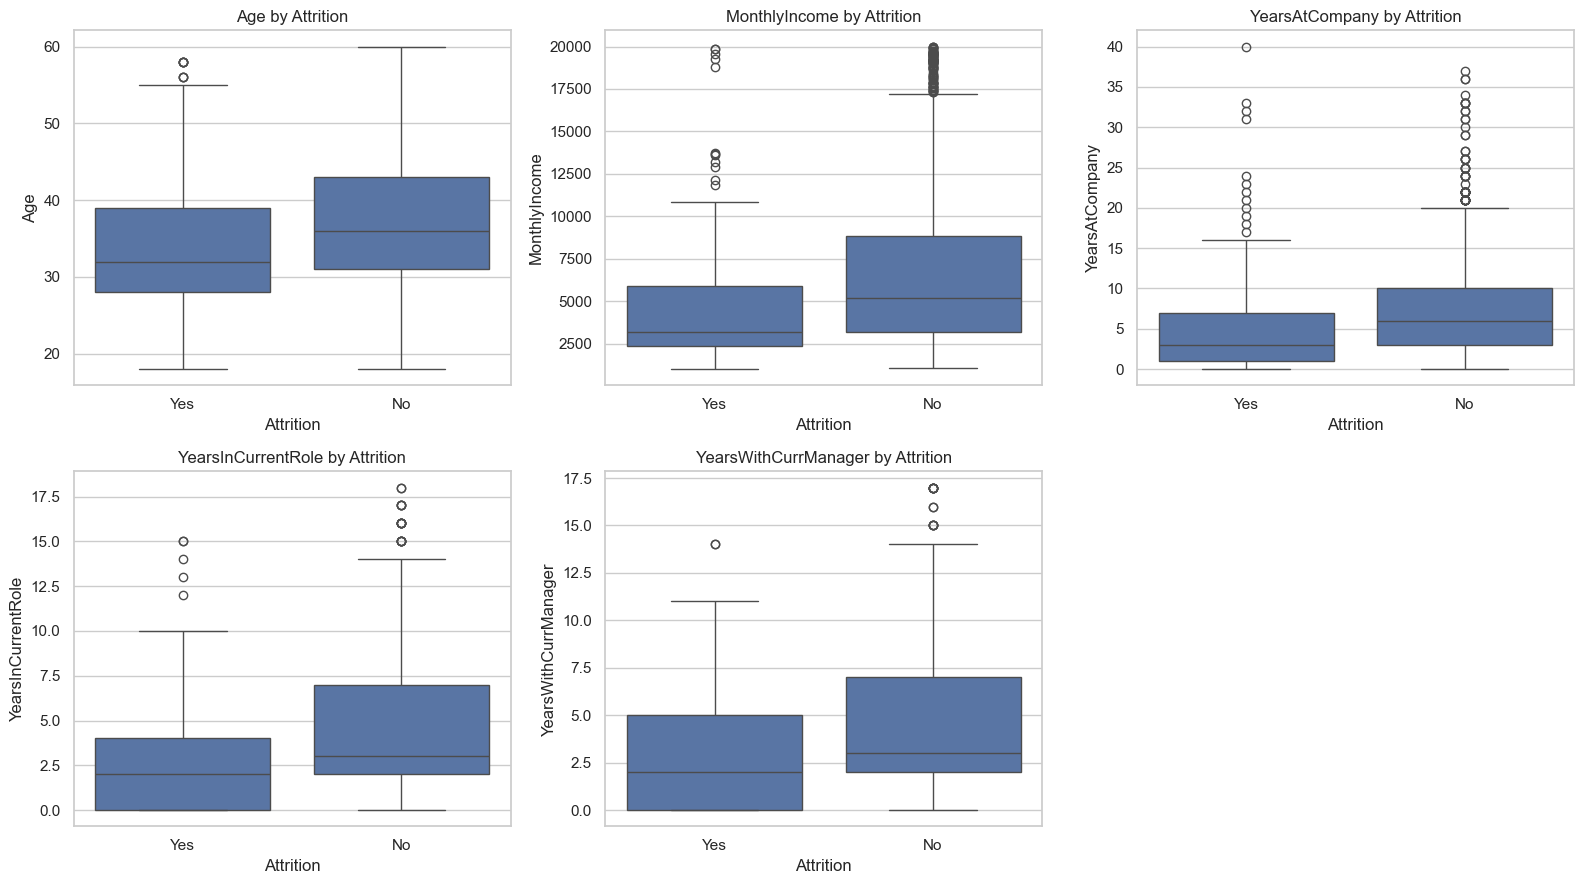

In [18]:
compare_cols = [
    "Age",
    "MonthlyIncome",
    "YearsAtCompany",
    "YearsInCurrentRole",
    "YearsWithCurrManager"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(compare_cols):
    sns.boxplot(
        data=hr_df,
        x="Attrition",
        y=col,
        ax=axes[i]
    )

    axes[i].set_title(f"{col} by Attrition")

axes[-1].axis("off")

plt.tight_layout()
plt.show()

In [19]:
group_statistics = (
    hr_df.groupby("Attrition")[compare_cols]
    .agg(["mean", "median", "std"])
    .round(2)
)

display(group_statistics)

Age              MonthlyIncome                  YearsAtCompany  \
            mean median   std          mean  median      std           mean   
Attrition                                                                     
No         37.56   36.0  8.89       6832.74  5204.0  4818.21           7.37   
Yes        33.61   32.0  9.69       4787.09  3202.0  3640.21           5.13   

                       YearsInCurrentRole              YearsWithCurrManager  \
          median   std               mean median   std                 mean   
Attrition                                                                     
No           6.0  6.10               4.48    3.0  3.65                 4.37   
Yes          3.0  5.95               2.90    2.0  3.17                 2.85   

                        
          median   std  
Attrition               
No           3.0  3.59  
Yes          2.0  3.14

## 9. 주요 변수 간 상관관계 분석

주요 수치형 변수 간의 상관관계를 확인하여 변수들 사이에 선형적인 관계가 존재하는지 탐색한다.

상관계수는 변수 간 관계의 방향과 강도를 파악하는 참고 지표로 활용한다.

단, 상관관계가 높다고 해서 한 변수가 다른 변수의 원인이라고 해석하지 않는다.

또한 식별자 및 명목형 변수를 수치형 상관관계 분석에 포함하지 않도록 주의한다.

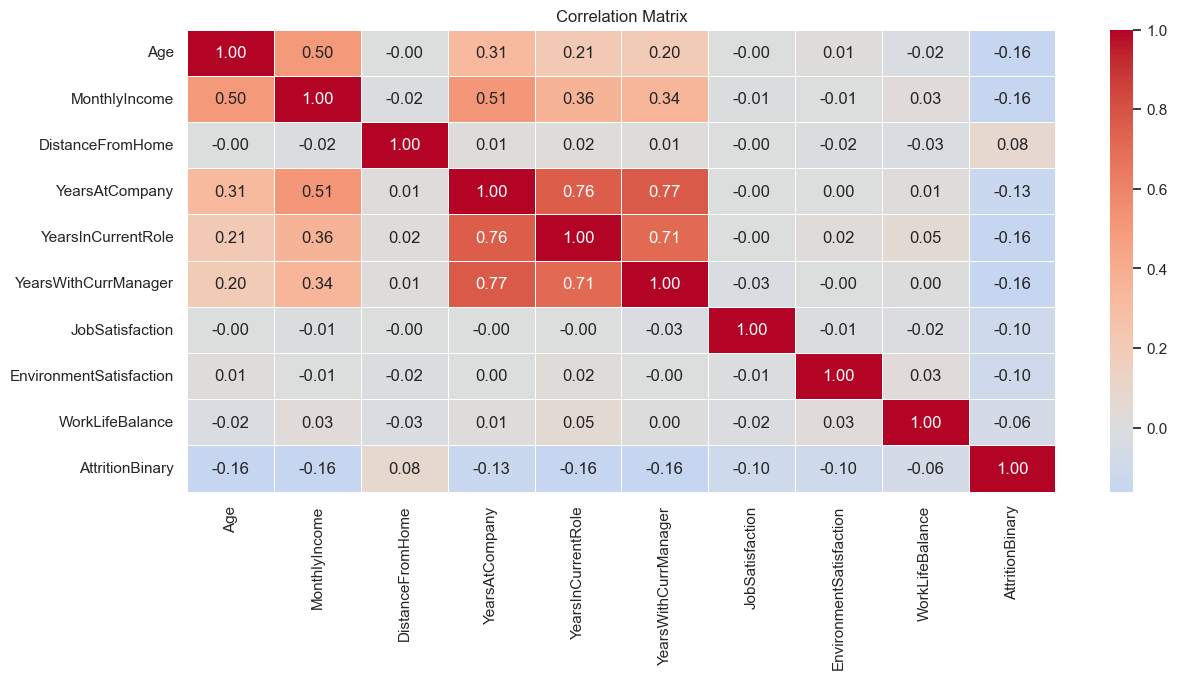

In [23]:
correlation_cols = [
    "Age",
    "MonthlyIncome",
    "DistanceFromHome",
    "YearsAtCompany",
    "YearsInCurrentRole",
    "YearsWithCurrManager",
    "JobSatisfaction",
    "EnvironmentSatisfaction",
    "WorkLifeBalance",
    "AttritionBinary"
]

corr = hr_df[correlation_cols].corr()

plt.figure(figsize=(14, 6))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Matrix")
plt.show()

## 10. EDA 종합 인사이트

### 1. 주요 분석 결과

앞선 탐색적 데이터 분석을 통해 직원의 인구통계학적 특성, 직무, 급여, 근속연수 및 근무 환경에 따른 이직률을 비교하였다.

주요 분석 결과는 다음과 같이 정리한다.

- 인구통계학적 특성: [연령, 성별, 결혼 여부에 따른 특징]
- 조직 및 직무 특성: [부서 및 직무별 이직률 특징]
- 급여 및 근속연수: [급여 구간 및 근속 기간에 따른 특징]
- 근무 환경: [초과근무 및 만족도에 따른 특징]

### 2. 핵심 인사이트

[가장 중요한 분석 결과 2~3개를 구체적인 수치와 함께 작성]

### 3. 비즈니스 관점의 시사점

이직률이 상대적으로 높은 직원 집단을 대상으로 근무 환경, 직무 특성 및 보상 체계 등을 추가적으로 검토할 필요가 있다.

다만 본 분석에서 확인한 결과는 변수 간의 연관성을 나타내므로 실제 이직 원인을 판단하기 위해서는 추가적인 통계 분석이 필요하다.

### 4. 다음 단계

EDA에서 도출한 주요 패턴과 초기 가설을 바탕으로 통계적 가설 검정을 수행한다.

이를 통해 집단별 이직률 차이가 통계적으로 유의한지 확인하고, 관찰된 차이가 우연에 의한 것인지 추가적으로 검토한다.